In [43]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\erden\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Tüm kütüphaneler başarıyla yüklendi!")
print("Pandas sürümü:", pd.__version__)
print("Scikit-learn sürümü:", sklearn.__version__)

Tüm kütüphaneler başarıyla yüklendi!
Pandas sürümü: 3.1.1
Scikit-learn sürümü: 1.9.1


In [45]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [46]:

# Veri setinin genel bilgilerini inceleyelim

print("Veri setinin boyutu:")
print(df.shape)

print("\nSütun isimleri:")
print(df.columns.tolist())

print("\nSütunların veri türleri:")
print(df.dtypes)

print("\nEksik veri sayıları:")
print(df.isnull().sum())


Veri setinin boyutu:
(7043, 21)

Sütun isimleri:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Sütunların veri türleri:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [47]:
print("Müşterilerin ayrılma durumu:")
print(df["Churn"].value_counts())

print("\nYüzdelik dağılım:")
print(df["Churn"].value_counts(normalize=True) * 100)

Müşterilerin ayrılma durumu:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Yüzdelik dağılım:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [48]:
# TotalCharges sütununu sayısal formata dönüştür
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Eksik değerleri kontrol et
print("Eksik değer sayıları:")
print(df.isnull().sum())

# Toplam eksik değer sayısı
print("\nToplam eksik değer:", df.isnull().sum().sum())

Eksik değer sayıları:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Toplam eksik değer: 11


In [49]:
df[df["TotalCharges"].isna()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [50]:
df = df.dropna(subset=["TotalCharges"])

print("Temizleme sonrası veri boyutu:", df.shape)
print("Toplam eksik değer:", df.isnull().sum().sum())

Temizleme sonrası veri boyutu: (7032, 21)
Toplam eksik değer: 0


In [51]:
df = df.dropna(subset=["TotalCharges"])

print("Temizleme sonrası veri boyutu:", df.shape)
print("Toplam eksik değer:", df.isnull().sum().sum())

Temizleme sonrası veri boyutu: (7032, 21)
Toplam eksik değer: 0


In [52]:
# Müşteri ID sütununu kaldırıyoruz
df = df.drop(columns=["customerID"])

# Güncel veri setini kontrol ediyoruz
print("Güncel veri boyutu:", df.shape)
print(df.head())

Güncel veri boyutu: (7032, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1

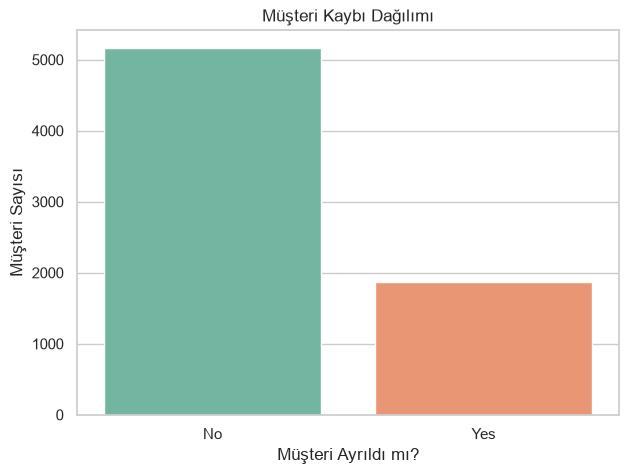

In [53]:
# Müşteri kaybı dağılımı

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False)

plt.title("Müşteri Kaybı Dağılımı")
plt.xlabel("Müşteri Ayrıldı mı?")
plt.ylabel("Müşteri Sayısı")

plt.show()

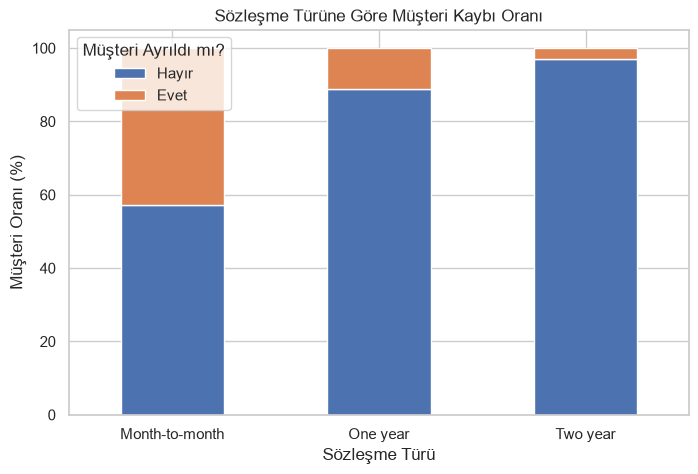

In [54]:
# Sözleşme türüne göre müşteri kaybı oranı

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Sözleşme Türüne Göre Müşteri Kaybı Oranı")
plt.xlabel("Sözleşme Türü")
plt.ylabel("Müşteri Oranı (%)")
plt.legend(title="Müşteri Ayrıldı mı?", labels=["Hayır", "Evet"])
plt.xticks(rotation=0)
plt.show()

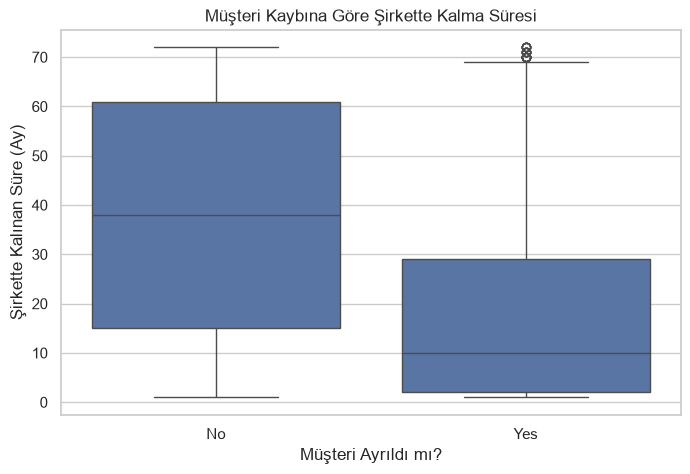

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Müşteri Kaybına Göre Şirkette Kalma Süresi")
plt.xlabel("Müşteri Ayrıldı mı?")
plt.ylabel("Şirkette Kalınan Süre (Ay)")

plt.show()

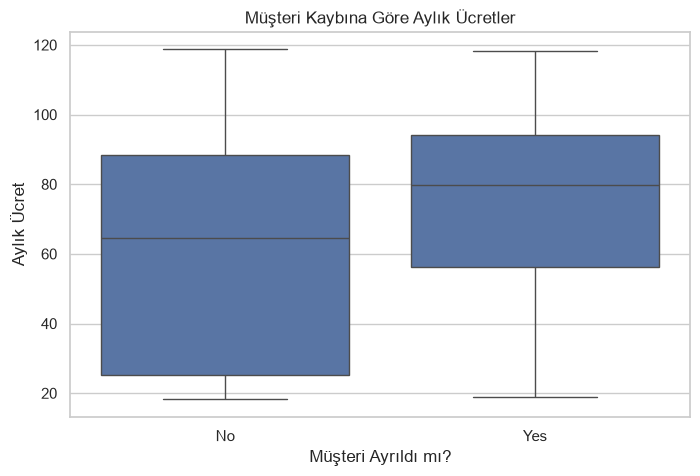

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Müşteri Kaybına Göre Aylık Ücretler")
plt.xlabel("Müşteri Ayrıldı mı?")
plt.ylabel("Aylık Ücret")

plt.show()

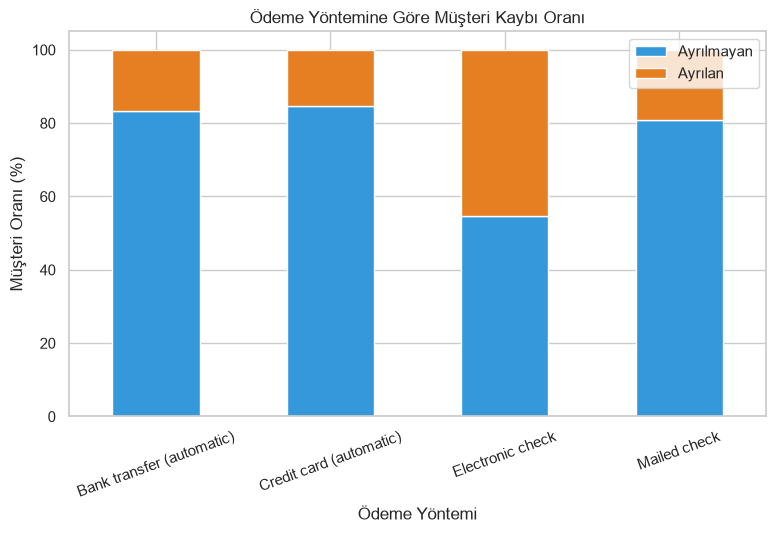

In [57]:
odeme_oran = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

odeme_oran.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#3498db", "#e67e22"]
)

plt.title("Ödeme Yöntemine Göre Müşteri Kaybı Oranı")
plt.xlabel("Ödeme Yöntemi")
plt.ylabel("Müşteri Oranı (%)")
plt.legend(["Ayrılmayan", "Ayrılan"])
plt.xticks(rotation=20)
plt.show()

In [58]:
# Tahmin edilecek değişken
y = df["Churn"].map({"No": 0, "Yes": 1})

# Tahmin için kullanılacak özellikler
X = df.drop(columns=["Churn", "customerID"], errors="ignore")

# Sayısal ve kategorik değişkenleri belirle
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Toplam müşteri:", len(df))
print("Tahmin için kullanılacak değişken sayısı:", X.shape[1])
print("Sayısal değişkenler:", list(numeric_features))
print("Kategorik değişkenler:", list(categorical_features))

Toplam müşteri: 7032
Tahmin için kullanılacak değişken sayısı: 19
Sayısal değişkenler: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Kategorik değişkenler: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\erden\AppData\Local\Temp\ipykernel_11104\1828254835.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [59]:
print("Veri seti boyutu:", df.shape)
print("X boyutu:", X.shape)
print("y boyutu:", y.shape)

print("\nSayısal değişkenler:")
print(list(numeric_features))

print("\nKategorik değişkenler:")
print(list(categorical_features))

print("\nHedef değişken dağılımı:")
print(y.value_counts())

Veri seti boyutu: (7032, 20)
X boyutu: (7032, 19)
y boyutu: (7032,)

Sayısal değişkenler:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Kategorik değişkenler:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Hedef değişken dağılımı:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim veri sayısı:", len(X_train))
print("Test veri sayısı:", len(X_test))

Eğitim veri sayısı: 5625
Test veri sayısı: 1407


In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Sayısal veriler
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kategorik veriler
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# İki veri türünü birleştir
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

# Modeli eğit
model.fit(X_train, y_train)

print("Model başarıyla eğitildi!")

Model başarıyla eğitildi!


Accuracy: 0.726
Precision: 0.49
Recall: 0.797

Sınıflandırma Raporu:
              precision    recall  f1-score   support

  Ayrılmayan       0.90      0.70      0.79      1033
     Ayrılan       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



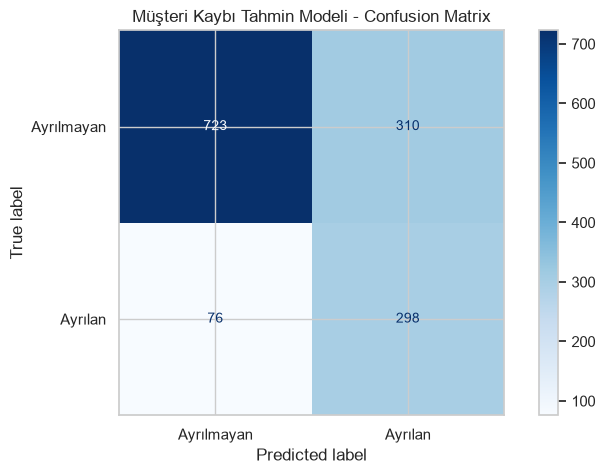

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Test verisi üzerinde tahmin
y_pred = model.predict(X_test)

# Başarı ölçütleri
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))

print("\nSınıflandırma Raporu:")
print(classification_report(
    y_test, y_pred,
    target_names=["Ayrılmayan", "Ayrılan"]
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Ayrılmayan", "Ayrılan"],
    cmap="Blues"
)

plt.title("Müşteri Kaybı Tahmin Modeli - Confusion Matrix")
plt.show()

In [63]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Karar ağacı modelini oluştur
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Modeli eğit
tree_model.fit(X_train, y_train)

# Tahmin yap
tree_pred = tree_model.predict(X_test)

# Başarı sonuçları
print("DECISION TREE SONUÇLARI")
print("-----------------------")
print("Accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print("Precision:", round(precision_score(y_test, tree_pred), 3))
print("Recall:", round(recall_score(y_test, tree_pred), 3))

DECISION TREE SONUÇLARI
-----------------------
Accuracy: 0.733
Precision: 0.499
Recall: 0.794


In [64]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, tree_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, tree_pred)
    ]
})

print(results.round(3))

                 Model  Accuracy  Precision  Recall
0  Logistic Regression     0.726      0.490   0.797
1        Decision Tree     0.733      0.499   0.794


In [65]:
# Yanlış tahmin edilen müşterileri bul
yanlis_tahminler = X_test.copy()

yanlis_tahminler["Gercek"] = y_test
yanlis_tahminler["Tahmin"] = y_pred
yanlis_tahminler["Tahmin_Dogru"] = (
    yanlis_tahminler["Gercek"] == yanlis_tahminler["Tahmin"]
)

# Yanlış tahminleri göster
yanlislar = yanlis_tahminler[
    yanlis_tahminler["Tahmin_Dogru"] == False
]

print("Yanlış tahmin sayısı:", len(yanlislar))
print(yanlislar[["Gercek", "Tahmin"]].head(10))

Yanlış tahmin sayısı: 386
      Gercek  Tahmin
619        0       1
3721       1       0
4283       0       1
6128       0       1
4653       1       0
5384       0       1
559        0       1
2300       1       0
2968       0       1
5738       1       0


In [66]:
print("Müşteri kaybı sınıf dağılımı:")
print(df["Churn"].value_counts())

print("\nYüzdelik dağılım:")
print(df["Churn"].value_counts(normalize=True) * 100)

Müşteri kaybı sınıf dağılımı:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Yüzdelik dağılım:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [67]:
degisken_aciklamalari = {
    "gender": "Müşterinin cinsiyeti",
    "SeniorCitizen": "Müşterinin 65 yaş ve üzeri olup olmadığı",
    "Partner": "Müşterinin eşi veya partneri olup olmadığı",
    "Dependents": "Müşterinin bakmakla yükümlü olduğu kişi bulunması",
    "tenure": "Müşterinin şirkette kaldığı ay sayısı",
    "PhoneService": "Telefon hizmeti kullanımı",
    "MultipleLines": "Birden fazla telefon hattı kullanımı",
    "InternetService": "İnternet hizmetinin türü",
    "OnlineSecurity": "Çevrimiçi güvenlik hizmeti",
    "OnlineBackup": "Çevrimiçi yedekleme hizmeti",
    "DeviceProtection": "Cihaz koruma hizmeti",
    "TechSupport": "Teknik destek hizmeti",
    "StreamingTV": "Televizyon yayın hizmeti",
    "StreamingMovies": "Film yayın hizmeti",
    "Contract": "Müşterinin sözleşme türü",
    "PaperlessBilling": "Elektronik fatura kullanımı",
    "PaymentMethod": "Ödeme yöntemi",
    "MonthlyCharges": "Aylık ödenen ücret",
    "TotalCharges": "Müşterinin toplam ödediği ücret",
    "Churn": "Müşterinin şirketten ayrılıp ayrılmadığı"
}

degisken_tablosu = pd.DataFrame([
    {"Değişken": sutun, "Açıklama": aciklama}
    for sutun, aciklama in degisken_aciklamalari.items()
    if sutun in df.columns
])

display(degisken_tablosu)

,Değişken,Açıklama
0,gender,Müşterinin cinsiyeti
1,SeniorCitizen,Müşterinin 65 yaş ve üzeri olup olmadığı
2,Partner,Müşterinin eşi veya partneri olup olmadığı
3,Dependents,Müşterinin bakmakla yükümlü olduğu kişi bulunması
4,tenure,Müşterinin şirkette kaldığı ay sayısı
5,PhoneService,Telefon hizmeti kullanımı
6,MultipleLines,Birden fazla telefon hattı kullanımı
7,InternetService,İnternet hizmetinin türü
8,OnlineSecurity,Çevrimiçi güvenlik hizmeti
9,OnlineBackup,Çevrimiçi yedekleme hizmeti


In [68]:
print("Veri setinin son boyutu:", df.shape)

print("\nEksik değer sayıları:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTekrarlanan satır sayısı:", df.duplicated().sum())

print("\nVeri türleri:")
print(df.dtypes)

print("\nHedef değişken dağılımı:")
print(df["Churn"].value_counts())

Veri setinin son boyutu: (7032, 20)

Eksik değer sayıları:
Series([], dtype: int64)

Tekrarlanan satır sayısı: 22

Veri türleri:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Hedef değişken dağılımı:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [69]:
degisken_aciklamalari = {
    "gender": "Müşterinin cinsiyeti",
    "SeniorCitizen": "Müşterinin 65 yaş ve üzeri olup olmadığı",
    "Partner": "Müşterinin eşi veya partneri olup olmadığı",
    "Dependents": "Müşterinin bakmakla yükümlü olduğu kişi bulunması",
    "tenure": "Müşterinin şirkette kaldığı ay sayısı",
    "PhoneService": "Telefon hizmeti kullanımı",
    "MultipleLines": "Birden fazla telefon hattı kullanımı",
    "InternetService": "İnternet hizmetinin türü",
    "OnlineSecurity": "Çevrimiçi güvenlik hizmeti",
    "OnlineBackup": "Çevrimiçi yedekleme hizmeti",
    "DeviceProtection": "Cihaz koruma hizmeti",
    "TechSupport": "Teknik destek hizmeti",
    "StreamingTV": "Televizyon yayın hizmeti",
    "StreamingMovies": "Film yayın hizmeti",
    "Contract": "Müşterinin sözleşme türü",
    "PaperlessBilling": "Elektronik fatura kullanımı",
    "PaymentMethod": "Ödeme yöntemi",
    "MonthlyCharges": "Aylık ödenen ücret",
    "TotalCharges": "Müşterinin toplam ödediği ücret",
    "Churn": "Müşterinin şirketten ayrılıp ayrılmadığı"
}

degisken_tablosu = pd.DataFrame([
    {"Değişken": sutun, "Açıklama": aciklama}
    for sutun, aciklama in degisken_aciklamalari.items()
    if sutun in df.columns
])

display(degisken_tablosu)

,Değişken,Açıklama
0,gender,Müşterinin cinsiyeti
1,SeniorCitizen,Müşterinin 65 yaş ve üzeri olup olmadığı
2,Partner,Müşterinin eşi veya partneri olup olmadığı
3,Dependents,Müşterinin bakmakla yükümlü olduğu kişi bulunması
4,tenure,Müşterinin şirkette kaldığı ay sayısı
5,PhoneService,Telefon hizmeti kullanımı
6,MultipleLines,Birden fazla telefon hattı kullanımı
7,InternetService,İnternet hizmetinin türü
8,OnlineSecurity,Çevrimiçi güvenlik hizmeti
9,OnlineBackup,Çevrimiçi yedekleme hizmeti


In [70]:
print("Veri setinin son boyutu:", df.shape)

print("\nEksik değer sayıları:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTekrarlanan satır sayısı:", df.duplicated().sum())

print("\nVeri türleri:")
print(df.dtypes)

print("\nHedef değişken dağılımı:")
print(df["Churn"].value_counts())

Veri setinin son boyutu: (7032, 20)

Eksik değer sayıları:
Series([], dtype: int64)

Tekrarlanan satır sayısı: 22

Veri türleri:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Hedef değişken dağılımı:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [71]:
# Her iki modelin hata türlerini inceleyelim

def hata_analizi(gercek, tahmin, model_adi):
    cm = confusion_matrix(gercek, tahmin, labels=[0, 1])

    tn, fp, fn, tp = cm.ravel()

    print(f"\n--- {model_adi} ---")
    print("Doğru ayrılmayan tahmini (TN):", tn)
    print("Yanlış ayrılma tahmini (FP):", fp)
    print("Kaçırılan ayrılma (FN):", fn)
    print("Doğru ayrılma tahmini (TP):", tp)

    print("Toplam yanlış tahmin:", fp + fn)

hata_analizi(y_test, y_pred, "Logistic Regression")
hata_analizi(y_test, tree_pred, "Decision Tree")


--- Logistic Regression ---
Doğru ayrılmayan tahmini (TN): 723
Yanlış ayrılma tahmini (FP): 310
Kaçırılan ayrılma (FN): 76
Doğru ayrılma tahmini (TP): 298
Toplam yanlış tahmin: 386

--- Decision Tree ---
Doğru ayrılmayan tahmini (TN): 735
Yanlış ayrılma tahmini (FP): 298
Kaçırılan ayrılma (FN): 77
Doğru ayrılma tahmini (TP): 297
Toplam yanlış tahmin: 375


In [72]:
# Örnek ekonomik maliyet senaryosu

fp_maliyeti = 100       # Gereksiz müdahale maliyeti
fn_maliyeti = 1500      # Kaybedilen müşteri maliyeti

modeller = {
    "Logistic Regression": (310, 76),
    "Decision Tree": (298, 77)
}

for model, (fp, fn) in modeller.items():
    toplam_maliyet = (fp * fp_maliyeti) + (fn * fn_maliyeti)

    print(f"\n{model}")
    print("FP maliyeti:", fp * fp_maliyeti)
    print("FN maliyeti:", fn * fn_maliyeti)
    print("Toplam ekonomik hata maliyeti:", toplam_maliyet)


Logistic Regression
FP maliyeti: 31000
FN maliyeti: 114000
Toplam ekonomik hata maliyeti: 145000

Decision Tree
FP maliyeti: 29800
FN maliyeti: 115500
Toplam ekonomik hata maliyeti: 145300


In [73]:
# Tekrarlanan kayıtları inceleme
tekrar_sayisi = df.duplicated().sum()

print("Tekrarlanan satır sayısı:", tekrar_sayisi)

# Tekrarlanan satırlardan örnekleri göster
tekrarlar = df[df.duplicated(keep=False)]

display(tekrarlar.head(10))

# Tekrarlanan kayıtların hedef değişken dağılımı
print("\nTekrarlanan kayıtların müşteri kaybı dağılımı:")
print(tekrarlar["Churn"].value_counts())

Tekrarlanan satır sayısı: 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
646,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
690,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
976,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes
1243,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,45.30,45.30,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes



Tekrarlanan kayıtların müşteri kaybı dağılımı:
Churn
Yes    24
No     18
Name: count, dtype: int64


In [74]:
# Modelin yanlış tahmin ettiği müşterileri inceleyelim

yanlis_tahminler = X_test.copy()

yanlis_tahminler["Gerçek Durum"] = y_test
yanlis_tahminler["Tahmin Edilen Durum"] = y_pred

yanlis_tahminler = yanlis_tahminler[
    yanlis_tahminler["Gerçek Durum"] !=
    yanlis_tahminler["Tahmin Edilen Durum"]
]

yanlis_tahminler["Hata Türü"] = np.where(
    (yanlis_tahminler["Gerçek Durum"] == 1),
    "Müşteri kaybı kaçırıldı (FN)",
    "Gereksiz kayıp tahmini (FP)"
)

print("Yanlış tahmin sayısı:", len(yanlis_tahminler))
display(yanlis_tahminler.head(10))

print("\nHata türlerinin dağılımı:")
print(yanlis_tahminler["Hata Türü"].value_counts())

Yanlış tahmin sayısı: 386


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Gerçek Durum,Tahmin Edilen Durum,Hata Türü
619,Female,0,No,No,7,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Bank transfer (automatic),78.55,522.95,0,1,Gereksiz kayıp tahmini (FP)
3721,Female,0,No,No,2,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.65,38.70,1,0,Müşteri kaybı kaçırıldı (FN)
4283,Male,1,Yes,No,4,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.20,280.35,0,1,Gereksiz kayıp tahmini (FP)
6128,Female,0,Yes,No,14,Yes,No,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,78.10,1122.40,0,1,Gereksiz kayıp tahmini (FP)
4653,Female,0,Yes,Yes,30,No,No phone service,DSL,No,No,...,Yes,Yes,Month-to-month,No,Credit card (automatic),51.20,1561.50,1,0,Müşteri kaybı kaçırıldı (FN)
5384,Female,0,No,No,4,Yes,Yes,DSL,No,No,...,Yes,No,Month-to-month,Yes,Mailed check,64.40,253.00,0,1,Gereksiz kayıp tahmini (FP)
559,Male,0,No,No,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,49.30,49.30,0,1,Gereksiz kayıp tahmini (FP)
2300,Female,0,Yes,Yes,48,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,One year,Yes,Credit card (automatic),103.25,5037.55,1,0,Müşteri kaybı kaçırıldı (FN)
2968,Male,0,No,No,3,Yes,No,Fiber optic,No,Yes,...,No,Yes,Month-to-month,No,Electronic check,90.40,268.45,0,1,Gereksiz kayıp tahmini (FP)
5738,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.60,20.60,1,0,Müşteri kaybı kaçırıldı (FN)



Hata türlerinin dağılımı:
Hata Türü
Gereksiz kayıp tahmini (FP)     310
Müşteri kaybı kaçırıldı (FN)     76
Name: count, dtype: int64


In [75]:

# ==========================================
# EKONOMİK ANALİZLER
# ==========================================

analysis_df = df.copy()

# 1. CHURN DEĞİŞKENİNİ SAYISAL FORMATA DÖNÜŞTÜR
analysis_df["Churn_Binary"] = (
    analysis_df["Churn"]
    .astype(str)
    .str.strip()
    .map({"No": 0, "Yes": 1})
)

# Dönüşüm kontrolü
if analysis_df["Churn_Binary"].isna().any():
    raise ValueError("Churn değişkeninde beklenmeyen veya eksik değer var.")

analysis_df["Churn_Binary"] = analysis_df["Churn_Binary"].astype(int)


# ==========================================
# 2. FİYATLANDIRMA VE MÜŞTERİ KAYBI
# ==========================================

analysis_df["Ücret Grubu"] = pd.qcut(
    analysis_df["MonthlyCharges"],
    q=4,
    labels=["Düşük", "Orta-Düşük", "Orta-Yüksek", "Yüksek"],
    duplicates="drop"
)

fiyat_analizi = analysis_df.groupby(
    "Ücret Grubu", observed=False
).agg(
    Musteri_Sayisi=("Churn_Binary", "count"),
    Ayrilma_Orani=("Churn_Binary", "mean"),
    Ortalama_Aylik_Ucret=("MonthlyCharges", "mean")
)

fiyat_analizi["Ayrilma_Orani"] *= 100

print("1. FİYAT GRUPLARINA GÖRE MÜŞTERİ KAYBI")
display(fiyat_analizi.round(2))


# ==========================================
# 3. MÜŞTERİ SADAKATİ VE ŞİRKETTE KALMA SÜRESİ
# ==========================================

analysis_df["Kıdem Grubu"] = pd.cut(
    analysis_df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Ay", "13-24 Ay", "25-48 Ay", "49-72 Ay"]
)

kidem_analizi = analysis_df.groupby(
    "Kıdem Grubu", observed=False
).agg(
    Musteri_Sayisi=("Churn_Binary", "count"),
    Ayrilma_Orani=("Churn_Binary", "mean")
)

kidem_analizi["Ayrilma_Orani"] *= 100

print("\n2. MÜŞTERİ KIDEMİNE GÖRE AYRILMA")
display(kidem_analizi.round(2))


# ==========================================
# 4. AYRILAN VE KALAN MÜŞTERİLERİN GELİR PROFİLİ
# ==========================================

gelir_analizi = analysis_df.groupby("Churn_Binary").agg(
    Musteri_Sayisi=("MonthlyCharges", "count"),
    Ortalama_Aylik_Ucret=("MonthlyCharges", "mean"),
    Ortalama_Toplam_Ucret=("TotalCharges", "mean")
)

gelir_analizi.index = ["Ayrılmayan", "Ayrılan"]

print("\n3. MÜŞTERİLERİN GELİR PROFİLİ")
display(gelir_analizi.round(2))


# ==========================================
# 5. SÖZLEŞME TÜRLERİNE GÖRE MÜŞTERİ KAYBI
# ==========================================

sozlesme_analizi = analysis_df.groupby(
    "Contract", observed=False
).agg(
    Musteri_Sayisi=("Churn_Binary", "count"),
    Ayrilma_Orani=("Churn_Binary", "mean"),
    Ortalama_Aylik_Ucret=("MonthlyCharges", "mean")
)

sozlesme_analizi["Ayrilma_Orani"] *= 100

print("\n4. SÖZLEŞME TÜRLERİNE GÖRE EKONOMİK ANALİZ")
display(sozlesme_analizi.round(2))


1. FİYAT GRUPLARINA GÖRE MÜŞTERİ KAYBI


,Musteri_Sayisi,Ayrilma_Orani,Ortalama_Aylik_Ucret
Ücret Grubu,,,
Düşük,1758,11.32,22.25
Orta-Düşük,1761,24.59,55.75
Orta-Yüksek,1755,37.55,80.34
Yüksek,1758,32.88,100.90



2. MÜŞTERİ KIDEMİNE GÖRE AYRILMA


,Musteri_Sayisi,Ayrilma_Orani
Kıdem Grubu,,
0-12 Ay,2175,47.68
13-24 Ay,1024,28.71
25-48 Ay,1594,20.39
49-72 Ay,2239,9.51



3. MÜŞTERİLERİN GELİR PROFİLİ


,Musteri_Sayisi,Ortalama_Aylik_Ucret,Ortalama_Toplam_Ucret
Ayrılmayan,5163,61.31,2555.34
Ayrılan,1869,74.44,1531.80



4. SÖZLEŞME TÜRLERİNE GÖRE EKONOMİK ANALİZ


,Musteri_Sayisi,Ayrilma_Orani,Ortalama_Aylik_Ucret
Contract,,,
Month-to-month,3875,42.71,66.40
One year,1472,11.28,65.08
Two year,1685,2.85,60.87


In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10

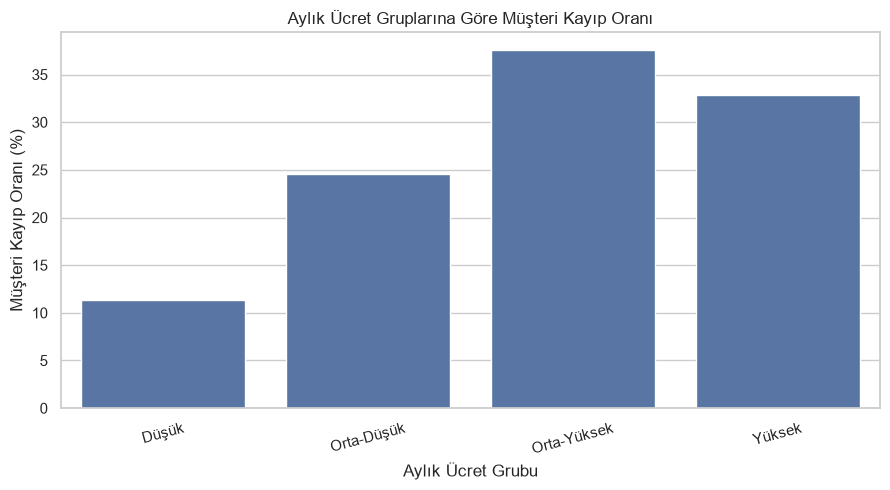

In [77]:
plt.figure()

sns.barplot(
    data=fiyat_analizi.reset_index(),
    x="Ücret Grubu",
    y="Ayrilma_Orani"
)

plt.title("Aylık Ücret Gruplarına Göre Müşteri Kayıp Oranı")
plt.xlabel("Aylık Ücret Grubu")
plt.ylabel("Müşteri Kayıp Oranı (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

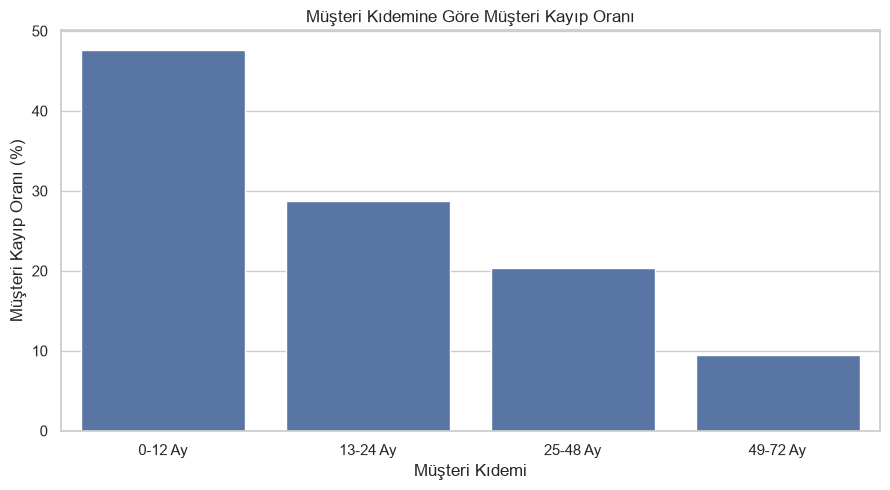

In [78]:
plt.figure()

sns.barplot(
    data=kidem_analizi.reset_index(),
    x="Kıdem Grubu",
    y="Ayrilma_Orani"
)

plt.title("Müşteri Kıdemine Göre Müşteri Kayıp Oranı")
plt.xlabel("Müşteri Kıdemi")
plt.ylabel("Müşteri Kayıp Oranı (%)")

plt.tight_layout()
plt.show()

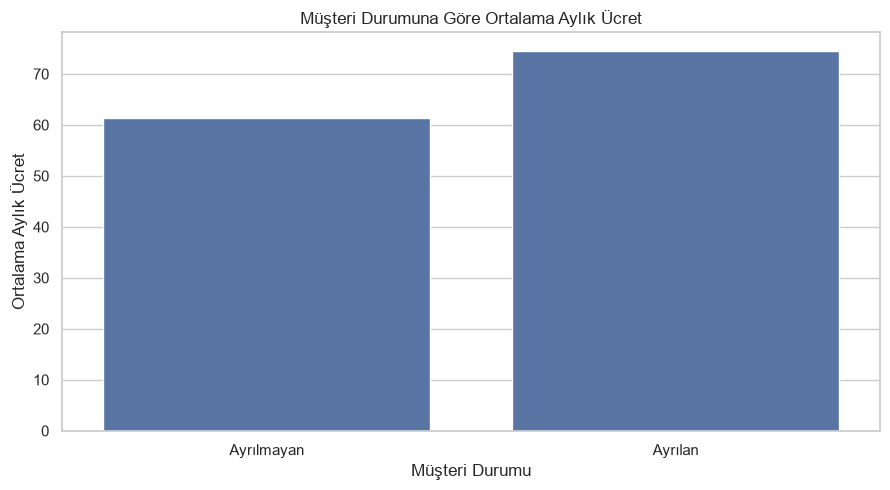

In [79]:
gelir_grafik = gelir_analizi.reset_index()

plt.figure()

sns.barplot(
    data=gelir_grafik,
    x="index",
    y="Ortalama_Aylik_Ucret"
)

plt.title("Müşteri Durumuna Göre Ortalama Aylık Ücret")
plt.xlabel("Müşteri Durumu")
plt.ylabel("Ortalama Aylık Ücret")

plt.xticks([0, 1], ["Ayrılmayan", "Ayrılan"])

plt.tight_layout()
plt.show()

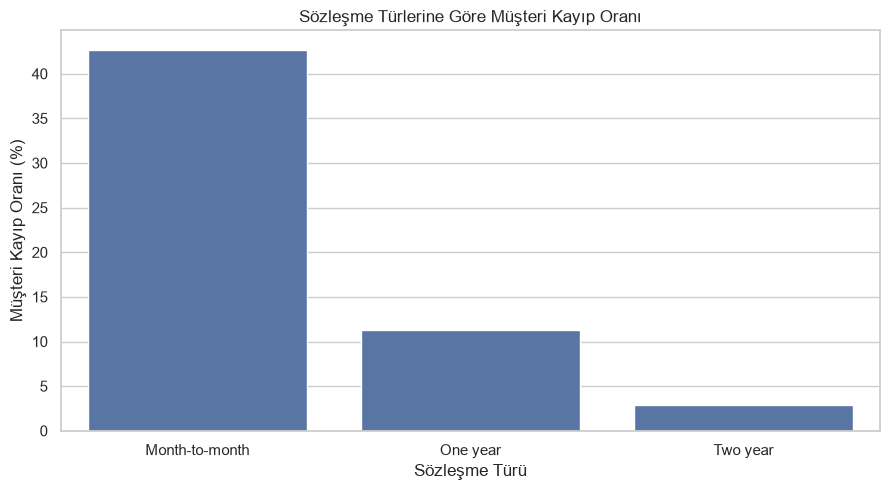

In [80]:
plt.figure()

sns.barplot(
    data=sozlesme_analizi.reset_index(),
    x="Contract",
    y="Ayrilma_Orani"
)

plt.title("Sözleşme Türlerine Göre Müşteri Kayıp Oranı")
plt.xlabel("Sözleşme Türü")
plt.ylabel("Müşteri Kayıp Oranı (%)")

plt.tight_layout()
plt.show()

## EKONOMİK ANALİZLERİN GENEL DEĞERLENDİRİLMESİ

Gerçekleştirilen analizler, müşteri kaybının yalnızca fiyat düzeyiyle açıklanamayacağını göstermektedir. Müşteri kıdemi ve sözleşme türü, müşteri devamlılığıyla güçlü ilişkiler sergilemektedir.

Özellikle ilk 12 ayda müşteri kayıp oranının %47,68 olması, yeni müşteri kazanımından sonra müşteri bağlılığını korumanın önemini ortaya koymaktadır. Bunun yanında aylık sözleşmeli müşterilerde kayıp oranının %42,71, iki yıllık sözleşmeli müşterilerde ise %2,85 olması, sözleşme süresinin müşteri devamlılığı açısından önemli bir değişken olduğunu göstermektedir.

Ücret gruplarına ilişkin bulgular ise fiyat ile müşteri kaybı arasında doğrusal bir ilişki bulunmadığına işaret etmektedir. Bu nedenle müşteri kaybını azaltmaya yönelik stratejiler geliştirilirken fiyatlandırma politikalarının yanı sıra müşteri deneyimi, sözleşme koşulları ve müşteri bağlılığı da dikkate alınmalıdır.

Bu bulgular betimsel ilişkileri ortaya koymaktadır; tek başına nedensellik kanıtı olarak değerlendirilmemelidir.

In [81]:
# YANLIŞ TAHMİNLERİN İNCELENMESİ

yanlis_tahminler = X_test.copy()

yanlis_tahminler["Gerçek Durum"] = y_test
yanlis_tahminler["Tahmin Edilen Durum"] = y_pred

yanlis_tahminler = yanlis_tahminler[
    yanlis_tahminler["Gerçek Durum"] != yanlis_tahminler["Tahmin Edilen Durum"]
]

yanlis_tahminler["Hata Türü"] = np.where(
    yanlis_tahminler["Gerçek Durum"] == 1,
    "FN - Gerçek müşteri kaybı kaçırıldı",
    "FP - Gereksiz müşteri kaybı tahmini"
)

print("Toplam yanlış tahmin:", len(yanlis_tahminler))

print("\nHata türlerine göre dağılım:")
display(yanlis_tahminler["Hata Türü"].value_counts())

display(yanlis_tahminler.head(10))

Toplam yanlış tahmin: 386

Hata türlerine göre dağılım:


Hata Türü
FP - Gereksiz müşteri kaybı tahmini    310
FN - Gerçek müşteri kaybı kaçırıldı     76
Name: count, dtype: int64

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Gerçek Durum,Tahmin Edilen Durum,Hata Türü
619,Female,0,No,No,7,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Bank transfer (automatic),78.55,522.95,0,1,FP - Gereksiz müşteri kaybı tahmini
3721,Female,0,No,No,2,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.65,38.70,1,0,FN - Gerçek müşteri kaybı kaçırıldı
4283,Male,1,Yes,No,4,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.20,280.35,0,1,FP - Gereksiz müşteri kaybı tahmini
6128,Female,0,Yes,No,14,Yes,No,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,78.10,1122.40,0,1,FP - Gereksiz müşteri kaybı tahmini
4653,Female,0,Yes,Yes,30,No,No phone service,DSL,No,No,...,Yes,Yes,Month-to-month,No,Credit card (automatic),51.20,1561.50,1,0,FN - Gerçek müşteri kaybı kaçırıldı
5384,Female,0,No,No,4,Yes,Yes,DSL,No,No,...,Yes,No,Month-to-month,Yes,Mailed check,64.40,253.00,0,1,FP - Gereksiz müşteri kaybı tahmini
559,Male,0,No,No,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,49.30,49.30,0,1,FP - Gereksiz müşteri kaybı tahmini
2300,Female,0,Yes,Yes,48,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,One year,Yes,Credit card (automatic),103.25,5037.55,1,0,FN - Gerçek müşteri kaybı kaçırıldı
2968,Male,0,No,No,3,Yes,No,Fiber optic,No,Yes,...,No,Yes,Month-to-month,No,Electronic check,90.40,268.45,0,1,FP - Gereksiz müşteri kaybı tahmini
5738,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.60,20.60,1,0,FN - Gerçek müşteri kaybı kaçırıldı


### Yanlış Sınıflandırmaların Ekonomik Değerlendirilmesi

Lojistik Regresyon modelinin test verisi üzerindeki tahminleri incelendiğinde toplam 386 yanlış sınıflandırma yapıldığı görülmektedir. Bu hataların 310'u yanlış pozitif (FP), 76'sı ise yanlış negatif (FN) sınıflandırmadır.

Yanlış pozitif sınıflandırmalar, gerçekte hizmet almaya devam edecek müşterilerin ayrılacak olarak tahmin edilmesini ifade etmektedir. Bu durum, işletmenin gereksiz indirim ve müşteri elde tutma kampanyaları nedeniyle ek maliyet üstlenmesine yol açabilir.

Yanlış negatif sınıflandırmalar ise gerçekte hizmetten ayrılacak müşterilerin model tarafından tespit edilememesidir. Bu hata türü, müşteri kaybını önlemeye yönelik müdahale fırsatının kaçırılması ve gelecekte elde edilebilecek gelirlerin kaybedilmesi riskini taşımaktadır.

Bu nedenle model performansı yalnızca doğruluk oranı üzerinden değerlendirilmemelidir. Yanlış sınıflandırmaların işletmeye yüklediği ekonomik maliyetler de karar sürecine dahil edilmelidir.

In [82]:
# YANLIŞ TAHMİNLERİN EKONOMİK MALİYETİ

FP_maliyeti = 100
FN_maliyeti = 1500

FP_sayisi = 310
FN_sayisi = 76

toplam_maliyet = (
    FP_sayisi * FP_maliyeti +
    FN_sayisi * FN_maliyeti
)

print("FP kaynaklı maliyet:", FP_sayisi * FP_maliyeti)
print("FN kaynaklı maliyet:", FN_sayisi * FN_maliyeti)
print("Toplam tahmini ekonomik maliyet:", toplam_maliyet)

FP kaynaklı maliyet: 31000
FN kaynaklı maliyet: 114000
Toplam tahmini ekonomik maliyet: 145000


In [83]:
# İKİ MODELİN EKONOMİK MALİYET KARŞILAŞTIRMASI

FP_maliyeti = 100
FN_maliyeti = 1500

modeller = {
    "Lojistik Regresyon": {
        "FP": 310,
        "FN": 76
    },
    "Decision Tree": {
        "FP": 298,
        "FN": 77
    }
}

for model, hata in modeller.items():
    maliyet = (
        hata["FP"] * FP_maliyeti +
        hata["FN"] * FN_maliyeti
    )

    print(model)
    print("FP maliyeti:", hata["FP"] * FP_maliyeti)
    print("FN maliyeti:", hata["FN"] * FN_maliyeti)
    print("Toplam ekonomik maliyet:", maliyet)
    print("-" * 35)

Lojistik Regresyon
FP maliyeti: 31000
FN maliyeti: 114000
Toplam ekonomik maliyet: 145000
-----------------------------------
Decision Tree
FP maliyeti: 29800
FN maliyeti: 115500
Toplam ekonomik maliyet: 145300
-----------------------------------


### Modellerin Ekonomik Maliyet Açısından Karşılaştırılması

Modellerin ekonomik performansları, yanlış sınıflandırmaların işletmeye yükleyebileceği varsayımsal maliyetler üzerinden değerlendirilmiştir. Bu kapsamda yanlış pozitif (FP) sınıflandırmanın maliyeti 100 birim, yanlış negatif (FN) sınıflandırmanın maliyeti ise 1.500 birim olarak kabul edilmiştir.

Analiz sonucunda Lojistik Regresyon modelinin toplam tahmini maliyeti 145.000 birim, Decision Tree modelinin toplam tahmini maliyeti ise 145.300 birim olarak hesaplanmıştır.

İki model arasındaki maliyet farkı oldukça sınırlıdır. Bununla birlikte Lojistik Regresyon modeli, belirlenen maliyet varsayımları altında daha düşük toplam maliyet üretmiştir. Bu bulgu, model seçiminde yalnızca doğruluk oranının değil, yanlış sınıflandırmaların ekonomik sonuçlarının da dikkate alınması gerektiğini göstermektedir.

**Not:** Kullanılan maliyet değerleri gerçek işletme verilerine değil, karşılaştırma amacıyla oluşturulmuş varsayımsal değerlere dayanmaktadır.

# GENEL SONUÇ VE DEĞERLENDİRME

Bu çalışmada, telekomünikasyon sektöründe müşteri kaybını (Customer Churn) etkileyen faktörlerin incelenmesi ve makine öğrenmesi yöntemleriyle müşteri kaybının tahmin edilmesi amaçlanmıştır.

Analiz sonuçları, müşteri kaybının özellikle sözleşme türü ve müşteri kıdemiyle ilişkili olduğunu göstermektedir. Aylık sözleşmeye sahip müşterilerde ayrılma oranı %42,71 iken iki yıllık sözleşmeye sahip müşterilerde bu oran %2,85 olarak hesaplanmıştır. Ayrıca ilk 12 ay içerisinde müşteri kayıp oranının %47,68 olması, müşteri ilişkisinin başlangıç döneminde elde tutma stratejilerinin önemini ortaya koymaktadır.

Makine öğrenmesi aşamasında Lojistik Regresyon ve Decision Tree algoritmaları kullanılmıştır. Her iki model de müşteri kaybı yaşayan müşterileri belirleme konusunda yaklaşık %79 düzeyinde Recall performansı göstermiştir. Bununla birlikte modellerin doğruluk oranları, sınıf dengesizliği dikkate alınarak değerlendirilmelidir.

Ekonomik değerlendirmede, yanlış negatif sınıflandırmaların işletme açısından daha yüksek maliyet oluşturabileceği varsayılmıştır. Belirlenen maliyet senaryosunda Lojistik Regresyon modeli 145.000 birim, Decision Tree modeli ise 145.300 birim tahmini maliyet üretmiştir.

Genel olarak çalışma, veri analitiği ve makine öğrenmesinin müşteri ilişkileri yönetimi, gelir sürekliliği ve işletmelerin kaynak tahsisi kararlarında kullanılabileceğini göstermektedir. Bununla birlikte elde edilen bulgular betimsel ve tahmine dayalıdır; değişkenler arasındaki ilişkiler tek başına nedensellik kanıtı olarak değerlendirilmemelidir.

In [84]:
# Tahmin yapabilen mevcut model nesnelerini bulalım

for isim, nesne in globals().items():
    if hasattr(nesne, "predict_proba"):
        print(isim, type(nesne).__name__)

Pipeline ABCMeta
LogisticRegression type
DecisionTreeClassifier ABCMeta
tree_model Pipeline


In [85]:
# MÜŞTERİ KAYIP RİSKİ ANALİZİ

# Test verisindeki müşterilerin ayrılma olasılıklarını hesapla
risk_olasiliklari = tree_model.predict_proba(X_test)[:, 1]

# Sonuçları tabloya dönüştür
risk_df = pd.DataFrame({
    "Ayrılma Olasılığı (%)": risk_olasiliklari * 100,
    "Gerçek Durum": y_test
}, index=X_test.index)

# Risk seviyelerini belirle
risk_df["Risk Seviyesi"] = pd.cut(
    risk_df["Ayrılma Olasılığı (%)"],
    bins=[-1, 30, 60, 100],
    labels=["Düşük Risk", "Orta Risk", "Yüksek Risk"]
)

# En yüksek riskli 10 müşteriyi göster
risk_df = risk_df.sort_values(
    "Ayrılma Olasılığı (%)",
    ascending=False
)

display(risk_df.head(10).round(2))

,Ayrılma Olasılığı (%),Gerçek Durum,Risk Seviyesi
1731,95.31,1,Yüksek Risk
2888,95.31,1,Yüksek Risk
6612,95.31,1,Yüksek Risk
2607,95.31,1,Yüksek Risk
3328,95.31,0,Yüksek Risk
2911,95.31,1,Yüksek Risk
2517,95.31,1,Yüksek Risk
2464,95.31,1,Yüksek Risk
383,95.31,1,Yüksek Risk
2510,95.31,1,Yüksek Risk


Risk Seviyesi
Düşük Risk     634
Yüksek Risk    534
Orta Risk      239
Name: count, dtype: int64

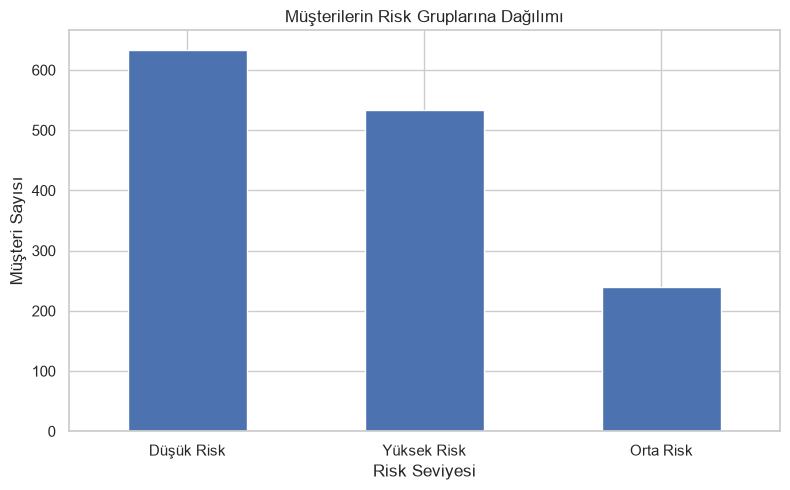

In [86]:
# RİSK GRUPLARININ DAĞILIMI

risk_dagilimi = risk_df["Risk Seviyesi"].value_counts()

display(risk_dagilimi)

# Risk gruplarını grafikle göster
plt.figure(figsize=(8, 5))

risk_dagilimi.plot(kind="bar")

plt.title("Müşterilerin Risk Gruplarına Dağılımı")
plt.xlabel("Risk Seviyesi")
plt.ylabel("Müşteri Sayısı")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


### Müşteri Kayıp Riskinin Ekonomik Açıdan Değerlendirilmesi

Decision Tree modeli kullanılarak test veri setindeki müşteriler ayrılma olasılıklarına göre düşük, orta ve yüksek risk gruplarına ayrılmıştır. Analiz sonucunda 534 müşterinin yüksek risk, 239 müşterinin orta risk ve 634 müşterinin düşük risk grubunda yer aldığı görülmüştür.

Bu sınıflandırma, işletmelerin müşteri tutundurma bütçelerini daha etkin kullanabilmesine yardımcı olabilecek bir karar destek yaklaşımı sunmaktadır. Özellikle yüksek risk grubundaki müşterilere yönelik kişiselleştirilmiş teklifler, müşteri memnuniyeti çalışmaları ve sözleşme yenileme kampanyaları değerlendirilebilir.

Bununla birlikte yüksek risk grubundaki tüm müşterilerin ayrılacağı varsayılmamalıdır. Model çıktıları kesin sonuç değil, karar süreçlerini destekleyen tahminlerdir.


### 6. Grafik: Dijital Yayın Hizmetlerinin Müşteri Kayıp Oranına Etkisi

Bu grafikte müşterilerin StreamingTV ve StreamingMovies hizmetlerini kullanma durumlarına göre müşteri kayıp oranları incelenmiştir. İki dijital yayın hizmetinin farklı kullanım kombinasyonlarında müşteri kaybının nasıl değiştiği karşılaştırılmıştır.


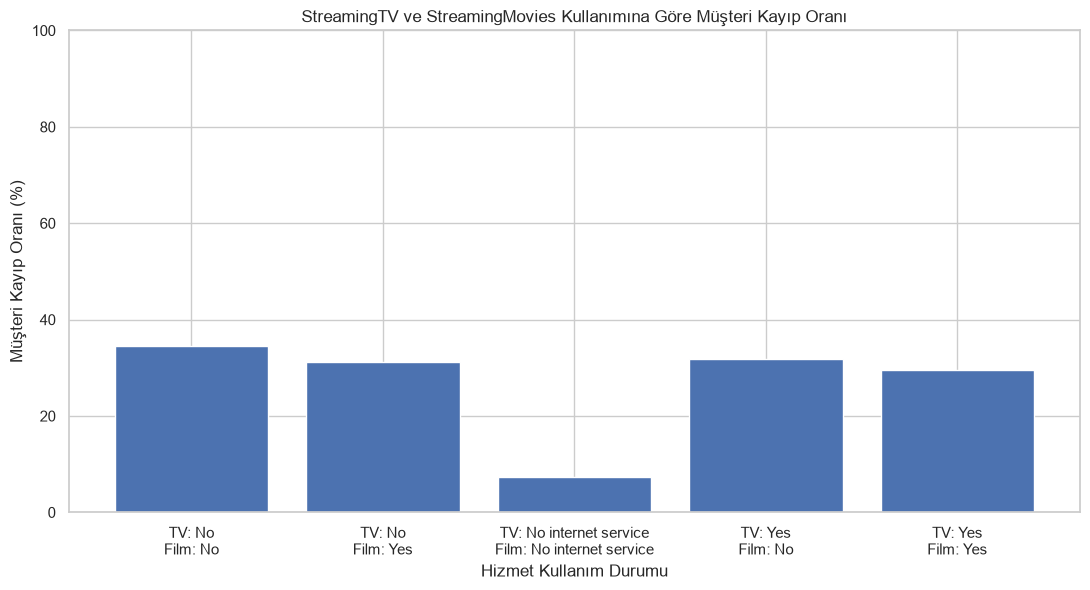

,StreamingTV,StreamingMovies,Müşteri Kayıp Oranı (%)
0,No,No,34.46
1,No,Yes,31.19
2,No internet service,No internet service,7.43
3,Yes,No,31.81
4,Yes,Yes,29.45


In [87]:

import matplotlib.pyplot as plt
import pandas as pd

# Veri setinin kopyasını oluşturuyoruz
grafik_df = df.copy()

# Churn değişkenini sayısal hale getiriyoruz
grafik_df["Churn_01"] = (
    grafik_df["Churn"]
    .astype(str)
    .str.strip()
    .map({"No": 0, "Yes": 1})
)

# Dönüşümün doğru yapıldığını kontrol ediyoruz
if grafik_df["Churn_01"].isna().any():
    raise ValueError("Churn sütununda beklenmeyen değerler var. Kontrol edin.")

# İki hizmetin kullanım durumuna göre müşteri kayıp oranlarını hesaplıyoruz
analiz = (
    grafik_df.groupby(["StreamingTV", "StreamingMovies"])["Churn_01"]
    .mean()
    .mul(100)
    .reset_index()
)

# Grafik etiketlerini oluşturuyoruz
analiz["Hizmet Kombinasyonu"] = (
    "TV: " + analiz["StreamingTV"].astype(str)
    + "\nFilm: " + analiz["StreamingMovies"].astype(str)
)

# Grafiği çiziyoruz
plt.figure(figsize=(11, 6))

plt.bar(
    analiz["Hizmet Kombinasyonu"],
    analiz["Churn_01"]
)

plt.title("StreamingTV ve StreamingMovies Kullanımına Göre Müşteri Kayıp Oranı")
plt.xlabel("Hizmet Kullanım Durumu")
plt.ylabel("Müşteri Kayıp Oranı (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# Hesaplanan oranları tablo halinde gösteriyoruz
display(
    analiz[["StreamingTV", "StreamingMovies", "Churn_01"]]
    .rename(columns={
        "Churn_01": "Müşteri Kayıp Oranı (%)"
    })
    .round(2)
)



### 7. Grafik: Aile ve Hane Yapısına Göre Müşteri Kayıp Oranı

Bu grafikte müşterilerin partner sahibi olma (Partner) ve bakmakla yükümlü oldukları kişilerin bulunma (Dependents) durumlarına göre müşteri kayıp oranları incelenmiştir. Amaç, müşterilerin aile ve hane yapıları ile aboneliklerini sonlandırma davranışları arasında bir ilişki olup olmadığını değerlendirmektir.


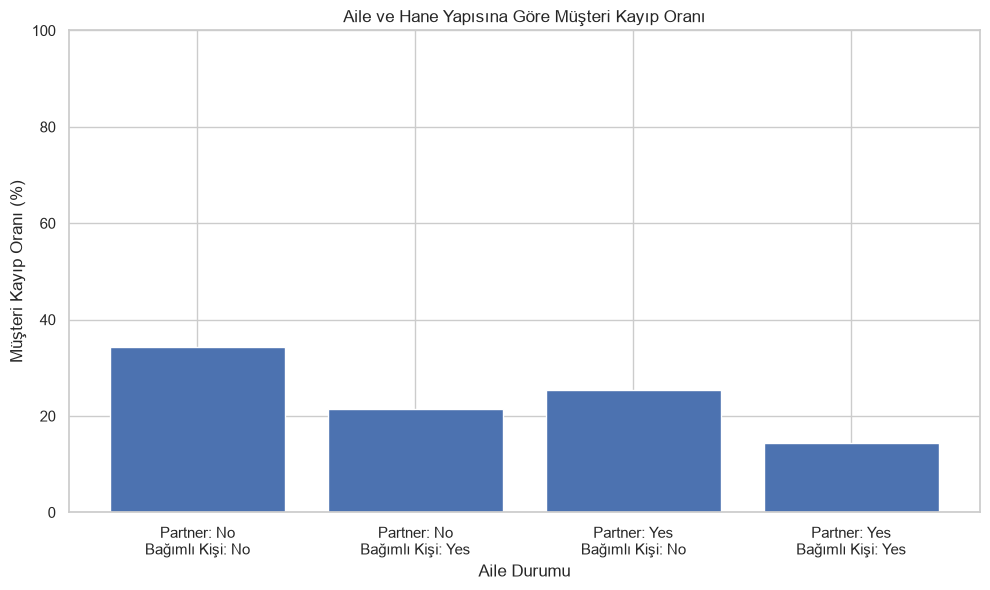

,Partner,Dependents,Müşteri Kayıp Oranı (%)
0,No,No,34.24
1,No,Yes,21.45
2,Yes,No,25.41
3,Yes,Yes,14.31


In [88]:

import matplotlib.pyplot as plt

grafik_df = df.copy()

grafik_df["Churn_01"] = (
    grafik_df["Churn"]
    .astype(str)
    .str.strip()
    .map({"No": 0, "Yes": 1})
)

if grafik_df["Churn_01"].isna().any():
    raise ValueError("Churn değerlerinde beklenmeyen bir kategori var.")

# Partner ve Dependents kombinasyonlarına göre kayıp oranı
analiz = (
    grafik_df.groupby(["Partner", "Dependents"])["Churn_01"]
    .mean()
    .mul(100)
    .reset_index()
)

analiz["Aile Durumu"] = (
    "Partner: " + analiz["Partner"].astype(str)
    + "\nBağımlı Kişi: " + analiz["Dependents"].astype(str)
)

# Grafik
plt.figure(figsize=(10, 6))

plt.bar(
    analiz["Aile Durumu"],
    analiz["Churn_01"]
)

plt.title("Aile ve Hane Yapısına Göre Müşteri Kayıp Oranı")
plt.xlabel("Aile Durumu")
plt.ylabel("Müşteri Kayıp Oranı (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Sonuç tablosu
display(
    analiz[["Partner", "Dependents", "Churn_01"]]
    .rename(columns={
        "Churn_01": "Müşteri Kayıp Oranı (%)"
    })
    .round(2)
)



### 8. Grafik: Telefon Hizmeti ve Çoklu Hat Kullanımına Göre Müşteri Kayıp Oranı

Bu grafikte müşterilerin telefon hizmeti (PhoneService) ve birden fazla telefon hattına sahip olma (MultipleLines) durumlarına göre müşteri kayıp oranları incelenmiştir. Amaç, telefon hizmetinin ve çoklu hat kullanımının müşteri kaybıyla ilişkisini karşılaştırmalı olarak değerlendirmektir.


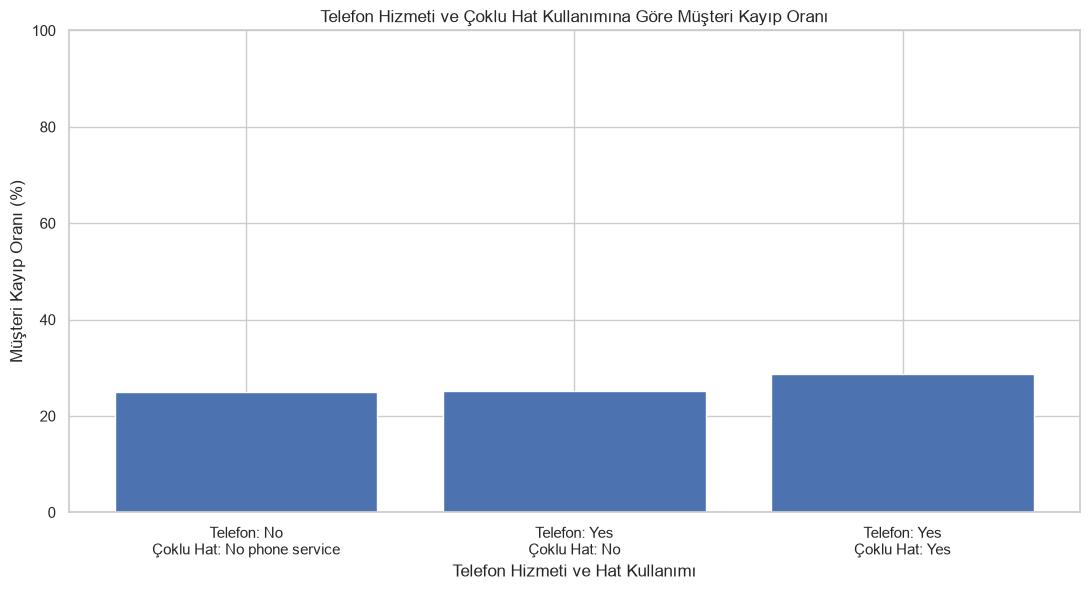

,PhoneService,MultipleLines,Müşteri Kayıp Oranı (%)
0,No,No phone service,25.00
1,Yes,No,25.08
2,Yes,Yes,28.65


In [89]:

import matplotlib.pyplot as plt
import pandas as pd

grafik_df = df.copy()

# Churn değişkenini sayısal hale getir
grafik_df["Churn_01"] = (
    grafik_df["Churn"]
    .astype(str)
    .str.strip()
    .map({"No": 0, "Yes": 1})
)

if grafik_df["Churn_01"].isna().any():
    raise ValueError("Churn sütununda beklenmeyen değerler var.")

# Telefon hizmeti ve çoklu hat kombinasyonlarına göre analiz
analiz = (
    grafik_df.groupby(["PhoneService", "MultipleLines"])["Churn_01"]
    .mean()
    .mul(100)
    .reset_index()
)

# Grafik etiketleri
analiz["Telefon Kullanımı"] = (
    "Telefon: " + analiz["PhoneService"].astype(str)
    + "\nÇoklu Hat: " + analiz["MultipleLines"].astype(str)
)

# Grafiği oluştur
plt.figure(figsize=(11, 6))

plt.bar(
    analiz["Telefon Kullanımı"],
    analiz["Churn_01"]
)

plt.title("Telefon Hizmeti ve Çoklu Hat Kullanımına Göre Müşteri Kayıp Oranı")
plt.xlabel("Telefon Hizmeti ve Hat Kullanımı")
plt.ylabel("Müşteri Kayıp Oranı (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Sonuç tablosu
display(
    analiz[["PhoneService", "MultipleLines", "Churn_01"]]
    .rename(columns={
        "Churn_01": "Müşteri Kayıp Oranı (%)"
    })
    .round(2)
)



**Ekonomik Değerlendirme:**

Telefon hizmeti ve çoklu hat kullanımına göre müşteri kayıp oranları incelendiğinde, birden fazla telefon hattı kullanan müşterilerin kayıp oranının %28,65 ile diğer gruplardan daha yüksek olduğu görülmektedir. Telefon hizmeti kullanmayan müşterilerde bu oran %25,00, tek hat kullanan müşterilerde ise %25,08'dir.

Bu bulgu, çoklu hat kullanan müşterilerde müşteri kaybı riskinin daha yüksek olabileceğini göstermektedir. İşletme, bu müşteri grubunun hizmet memnuniyetini ve ihtiyaçlarını inceleyerek müşteri elde tutma stratejileri geliştirebilir. Ancak oranlar arasındaki fark tek başına çoklu hat kullanımının müşteri kaybına neden olduğunu kanıtlamaz.



**Ekonomik Değerlendirme:**

StreamingTV ve StreamingMovies hizmetlerinin kullanım durumlarına göre müşteri kayıp oranları incelendiğinde, her iki hizmeti de kullanmayan internet müşterilerinde kayıp oranının %34,46 ile en yüksek olduğu görülmektedir. Her iki hizmeti kullanan müşterilerde bu oran %29,45'e düşmektedir. İnternet hizmeti bulunmayan müşterilerde ise kayıp oranı %7,43'tür.

Bu bulgular, dijital yayın hizmetlerinin müşterilere sunulan ek değer ve hizmet çeşitliliği açısından müşteri bağlılığıyla ilişkili olabileceğini göstermektedir. İşletme, dijital hizmet kullanmayan internet müşterilerine yönelik paket ve hizmet geliştirme stratejileri uygulayabilir. Ancak bu oranlar tek başına dijital yayın hizmetlerinin müşteri kaybını azalttığını kanıtlamaz.
